In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Our training dataset
X = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([30, 40, 50, 60, 70], dtype=float)

print("Features:", X)
print("Target:", y)
print("Number of samples:", len(X))

Features: [1. 2. 3. 4. 5.]
Target: [30. 40. 50. 60. 70.]
Number of samples: 5


In [2]:
def predict(X, weight, bias):
    """
    Generate predictions using Linear Regression.
    """
    return weight * X + bias

In [3]:
weight = 2
bias = 5

predictions = predict(X, weight, bias)

print("Predictions:", predictions)
print("Actual values:", y)

Predictions: [ 7.  9. 11. 13. 15.]
Actual values: [30. 40. 50. 60. 70.]


In [4]:
def mean_squared_error(y_true, y_pred):
    errors = y_true - y_pred
    return np.mean(errors ** 2)

In [5]:
weight = 0.0
bias = 0.0

predictions = predict(X, weight, bias)
loss = mean_squared_error(y, predictions)

print("Predictions:", predictions)
print("MSE:", loss)

Predictions: [0. 0. 0. 0. 0.]
MSE: 2700.0


In [6]:
def compute_gradients(X, y, weight, bias):
    """
    Calculate gradients of MSE with respect to weight and bias.
    """

    # Generate predictions
    predictions = predict(X, weight, bias)

    # Calculate prediction errors
    errors = predictions - y

    # Calculate gradients
    dw = (2 / len(X)) * np.sum(X * errors)
    db = (2 / len(X)) * np.sum(errors)

    return dw, db

In [7]:
weight = 0.0
bias = 0.0

dw, db = compute_gradients(X, y, weight, bias)

print("Weight gradient:", dw)
print("Bias gradient:", db)


Weight gradient: -340.0
Bias gradient: -100.0


In [8]:
def train_linear_regression(X, y, learning_rate=0.01, epochs=5000):

    # Initialize parameters
    weight = 0.0
    bias = 0.0

    # Store loss after each iteration
    loss_history = []

    for epoch in range(epochs):

        # Step 1: Generate predictions
        predictions = predict(X, weight, bias)

        # Step 2: Calculate loss
        loss = mean_squared_error(y, predictions)

        # Step 3: Calculate gradients
        dw, db = compute_gradients(X, y, weight, bias)

        # Step 4: Update parameters
        weight -= learning_rate * dw
        bias -= learning_rate * db

        # Record loss
        loss_history.append(loss)

    return weight, bias, loss_history

In [9]:
weight, bias, loss_history = train_linear_regression(
    X,
    y,
    learning_rate=0.01,
    epochs=5000
)

print("Learned weight:", weight)
print("Learned bias:", bias)
print("Initial loss:", loss_history[0])
print("Final loss:", loss_history[-1])

Learned weight: 10.000000196126466
Learned bias: 19.999999291921224
Initial loss: 2700.0
Final loss: 9.18793529957461e-14


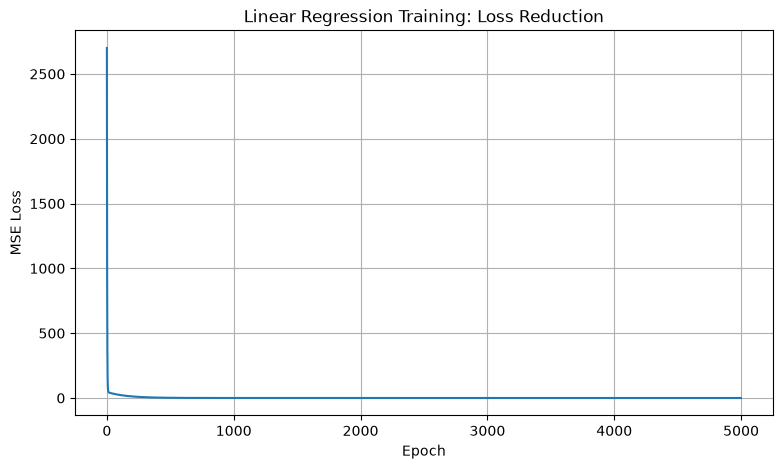

In [10]:
plt.figure(figsize=(9, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Linear Regression Training: Loss Reduction")

plt.grid(True)
plt.show()

In [11]:
predictions = predict(X, weight, bias)

results = pd.DataFrame({
    "Actual": y,
    "Predicted": predictions
})

print(results)

   Actual  Predicted
0    30.0  29.999999
1    40.0  40.000000
2    50.0  50.000000
3    60.0  60.000000
4    70.0  70.000000


In [12]:
print("Learned weight:", weight)
print("Learned bias:", bias)
print("Initial loss:", loss_history[0])
print("Final loss:", loss_history[-1])

Learned weight: 10.000000196126466
Learned bias: 19.999999291921224
Initial loss: 2700.0
Final loss: 9.18793529957461e-14


In [13]:
predictions = predict(X, weight, bias)

results = pd.DataFrame({
    "Actual": y,
    "Predicted": predictions
})

display(results)

,Actual,Predicted
0,30.0,29.999999
1,40.0,40.000000
2,50.0,50.000000
3,60.0,60.000000
4,70.0,70.000000


In [14]:
new_data = np.array([6, 7, 8], dtype=float)

new_predictions = predict(new_data, weight, bias)

print("New inputs:", new_data)
print("Predictions:", new_predictions)

New inputs: [6. 7. 8.]
Predictions: [ 80.00000047  90.00000066 100.00000086]


In [15]:
from sklearn.linear_model import LinearRegression

# Create model
sk_model = LinearRegression()

# Train model
sk_model.fit(X.reshape(-1, 1), y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[10.]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,20
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.16]


In [16]:
print("Sklearn weight:", sk_model.coef_[0])
print("Sklearn bias:", sk_model.intercept_)

Sklearn weight: 9.999999999999998
Sklearn bias: 20.000000000000007


In [17]:
sk_predictions = sk_model.predict(X.reshape(-1, 1))

comparison = pd.DataFrame({
    "Actual": y,
    "Our Model": predictions,
    "Sklearn Model": sk_predictions
})

display(comparison)

,Actual,Our Model,Sklearn Model
0,30.0,29.999999,30.0
1,40.0,40.000000,40.0
2,50.0,50.000000,50.0
3,60.0,60.000000,60.0
4,70.0,70.000000,70.0


In [18]:
# Generate a larger dataset
np.random.seed(42)

X_noisy = np.linspace(1, 100, 100)

# Actual relationship: y = 10x + 20
# Add random noise to simulate real-world observations
noise = np.random.normal(0, 30, 100)

y_noisy = 10 * X_noisy + 20 + noise

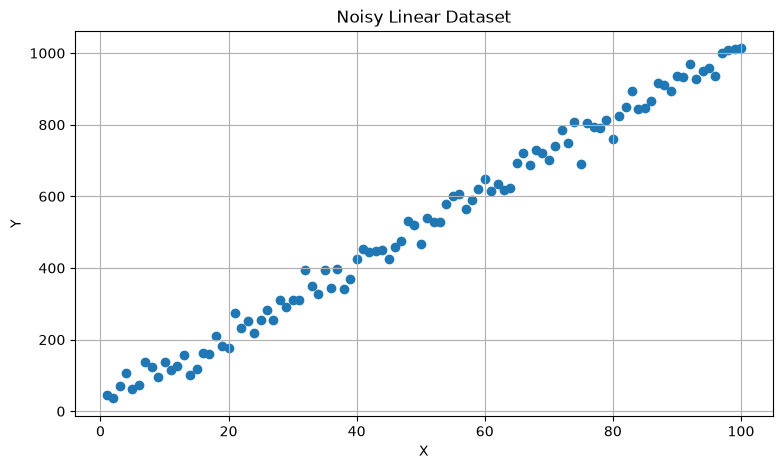

In [19]:
plt.figure(figsize=(9, 5))

plt.scatter(X_noisy, y_noisy)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Noisy Linear Dataset")

plt.grid(True)
plt.show()

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X_noisy,
    y_noisy,
    test_size=0.2,
    random_state=42
)

In [22]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (80,)
X_test: (20,)
y_train: (80,)
y_test: (20,)


In [23]:
noisy_weight, noisy_bias, noisy_loss_history = train_linear_regression(
    X_train,
    y_train,
    learning_rate=0.00001,
    epochs=10000
)


In [24]:
print("Learned weight:", noisy_weight)
print("Learned bias:", noisy_bias)
print("Final training loss:", noisy_loss_history[-1])

Learned weight: 10.239097032655136
Learned bias: 0.8187546297154131
Final training loss: 821.9177500601684


In [25]:
print("Learned weight:", noisy_weight)
print("Learned bias:", noisy_bias)
print("Final training loss:", noisy_loss_history[-1])

Learned weight: 10.239097032655136
Learned bias: 0.8187546297154131
Final training loss: 821.9177500601684


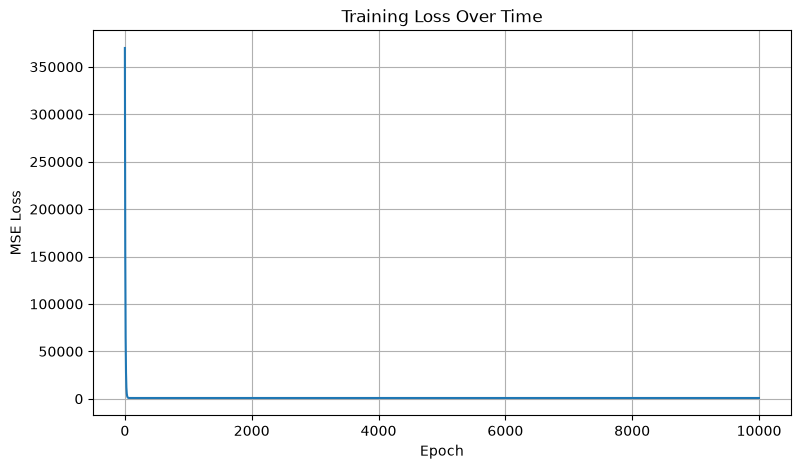

In [26]:
plt.figure(figsize=(9, 5))

plt.plot(noisy_loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss Over Time")

plt.grid(True)
plt.show()

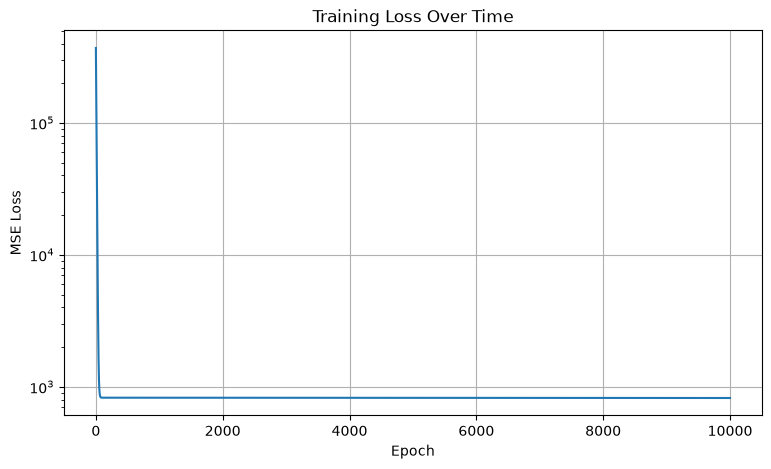

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(noisy_loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss Over Time")

plt.yscale("log")
plt.grid(True)
plt.show()

In [28]:
for epoch in [0, 10, 100, 1000, 5000, 9999]:
    print(f"Epoch {epoch + 1}: {noisy_loss_history[epoch]:.4f}")
    

Epoch 1: 369834.5212
Epoch 11: 86808.6015
Epoch 101: 826.5047
Epoch 1001: 825.9121
Epoch 5001: 824.0944
Epoch 10000: 821.9178


In [29]:
print("Minimum X:", X_train.min())
print("Maximum X:", X_train.max())
print("Mean X:", X_train.mean())


Minimum X: 2.0
Maximum X: 100.0
Mean X: 51.75


In [30]:
# Calculate statistics using training data only
X_mean = X_train.mean()
X_std = X_train.std()

# Standardize training features
X_train_scaled = (X_train - X_mean) / X_std

print("Original mean:", X_train.mean())
print("Original standard deviation:", X_train.std())

print("Scaled mean:", X_train_scaled.mean())
print("Scaled standard deviation:", X_train_scaled.std())

Original mean: 51.75
Original standard deviation: 28.868884633805997
Scaled mean: 1.1102230246251566e-17
Scaled standard deviation: 1.0


In [31]:
scaled_weight, scaled_bias, scaled_loss_history = train_linear_regression(
    X_train_scaled,
    y_train,
    learning_rate=0.01,
    epochs=10000
)

In [32]:
print("Learned weight:", scaled_weight)
print("Learned bias:", scaled_bias)

print("Initial loss:", scaled_loss_history[0])
print("Final loss:", scaled_loss_history[-1])

Learned weight: 289.745975548341
Learned bias: 533.9519346435395
Initial loss: 369834.52123059024
Final loss: 777.1223745480332


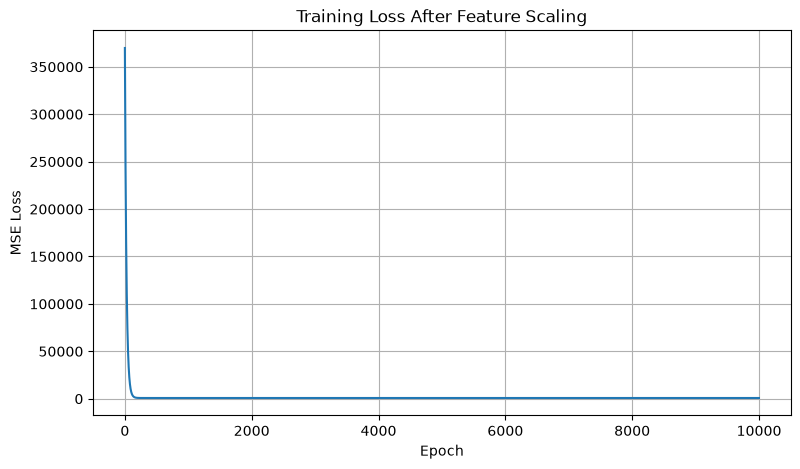

In [33]:
plt.figure(figsize=(9, 5))

plt.plot(scaled_loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss After Feature Scaling")

plt.grid(True)
plt.show()

In [34]:
print("Without scaling:", noisy_loss_history[-1])
print("With scaling:", scaled_loss_history[-1])

Without scaling: 821.9177500601684
With scaling: 777.1223745480332


In [35]:
# Convert parameters back to the original feature scale

original_weight = scaled_weight / X_std

original_bias = scaled_bias - original_weight * X_mean

print("Original weight:", original_weight)
print("Original bias:", original_bias)

Original weight: 10.036618290719936
Original bias: 14.55693809878278


In [36]:
# Use training statistics to transform test data
X_test_scaled = (X_test - X_mean) / X_std

# Predict using the trained parameters
y_test_predictions = predict(
    X_test_scaled,
    scaled_weight,
    scaled_bias
)

In [37]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_test_predictions)

mse = mean_squared_error(y_test, y_test_predictions)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_test_predictions)

print("Test MAE:", mae)
print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("Test R²:", r2)

Test MAE: 18.039370424949468
Test MSE: 559.838018061175
Test RMSE: 23.660896391750992
Test R²: 0.9931685690698473


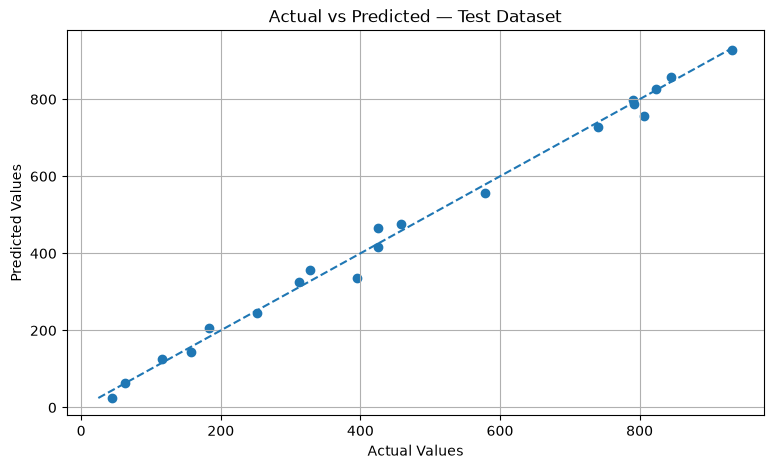

In [38]:
plt.figure(figsize=(9, 5))

plt.scatter(y_test, y_test_predictions)

# Ideal prediction line
minimum = min(y_test.min(), y_test_predictions.min())
maximum = max(y_test.max(), y_test_predictions.max())

plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted — Test Dataset")

plt.grid(True)
plt.show()
